In [1]:
import pandas as pd

df = pd.read_csv("../data/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
df = df.drop_duplicates()

In [8]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


In [4]:
df['Class'].value_counts(normalize=True).round(3)

Class
0    0.998
1    0.002
Name: proportion, dtype: float64

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [9]:
from sklearn.preprocessing import StandardScaler

preprocessor = StandardScaler()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


log_reg = LogisticRegression(random_state=42)
log_reg_pipeline = Pipeline([
    ("prep", preprocessor),
    ("logreg", log_reg)
])

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

kf = StratifiedKFold(shuffle=True, random_state=42, n_splits=3)
y_train_pred = cross_val_predict(log_reg_pipeline, X_train, y_train, cv= kf)

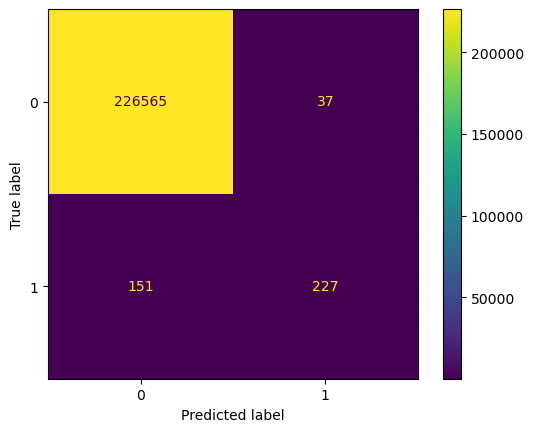

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)

In [24]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline      

smote = SMOTE(sampling_strategy=0.2, random_state=42)
X_res, y_res = smote.fit_resample(preprocessor.fit_transform(X_train), y_train)

print("Before:", y_train.value_counts().to_dict())
print("After :", pd.Series(y_res).value_counts().to_dict())

Before: {0: 226602, 1: 378}
After : {0: 226602, 1: 45320}


In [25]:
smote_pipeline = Pipeline([
    ("prep", StandardScaler()),
    ("smote", SMOTE(sampling_strategy=0.2, random_state=42)),
    ("logreg", log_reg)
])

y_train_pred = cross_val_predict(smote_pipeline, X_train, y_train, cv= kf)

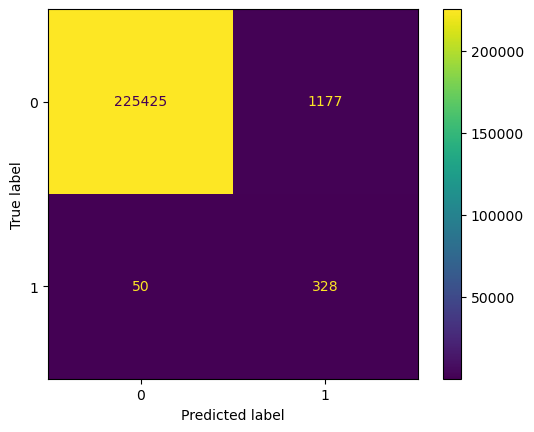

In [26]:
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)

In [27]:
from sklearn.model_selection import GridSearchCV


def perform_grid_search(model_pipe_line, param_grid, scoring_metric):
    """Run a grid search over `param_grid` for `model_pipe_line` and return the fitted GridSearchCV."""
    grid_search = GridSearchCV(
        estimator=model_pipe_line,
        param_grid=param_grid,
        scoring=scoring_metric,
        cv=kf,
        n_jobs=-1,
        verbose=1,
    )
    grid_search.fit(X_train, y_train)

    print("Best params:", grid_search.best_params_)
    print(f"Best {scoring_metric}: {grid_search.best_score_:.4f}")
    return grid_search


In [31]:
from sklearn.metrics import make_scorer, fbeta_score

f2_scorer = make_scorer(fbeta_score, beta=2)

In [29]:
param_grid = {
    "smote__sampling_strategy": [0.2, 0.5],
    "logreg__C": [0.1, 1, 10],
}
grid_search = perform_grid_search(smote_pipeline, param_grid, f2_scorer)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best params: {'logreg__C': 0.1, 'smote__sampling_strategy': 0.2}
Best make_scorer(fbeta_score, response_method='predict', beta=2): 0.5463


In [30]:
grid_search = perform_grid_search(smote_pipeline, param_grid, "average_precision")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best params: {'logreg__C': 0.1, 'smote__sampling_strategy': 0.5}
Best average_precision: 0.7553
